# ShopScope | See the market. Sell smarter.
**Data Entrepreneurship — Business intelligence proof of concept**

**Project team**

| Student name | Student ID |
| --- | --- |
| Nguyễn Đức Anh | 20262236M |
| Nguyễn Thị Thu Hiền | 20262330M |
| Ngô Xuân Kiên | 20262335M |
| Lê Lưu Ly | 20262340M |

**Decision:** Help small Vietnamese Shopee sellers choose a competitive, margin-aware asking price for a comparable diaper product.

**Evidence contract:** Easy Data's six-market historical snapshot (18 November 2025). A listing is not a transaction, a shop ID is not necessarily a company, and source counters are not audited demand. No market-size or current price claim is inferred from the workbook. All analytical figures and the JSON evidence bundle below are produced by this notebook; the pitch deck and report consume that bundle without copying metrics by hand.

Source: [Kaggle dataset](https://www.kaggle.com/datasets/johnphamed/shopee-diaper-listings-six-markets-november-2025) · [Publisher documentation](https://github.com/JohnPham-easydata/Shopee-Dataset/blob/main/README.md).


## 1. Reproducibility and data ingestion
Load all six workbooks, retain original columns, identify file hashes and verify the published observation and key counts. Do not publish raw data without permission.

In [1]:
from pathlib import Path
import os, re, json, hashlib, math, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Image, Markdown
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
ROOT = Path.cwd()
if not (ROOT/'data').exists() and (ROOT.parent/'data').exists(): ROOT = ROOT.parent
RAW = ROOT/'data'/'raw'
OUT = ROOT/'outputs'; FIG = OUT/'figures'; TAB = OUT/'tables'
for d in (FIG,TAB): d.mkdir(parents=True,exist_ok=True)
NAVY='#101B2D'; ORANGE='#F56636'; TEAL='#078C78'; GRAY='#64748B'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.labelcolor':NAVY,'text.color':NAVY,'axes.titleweight':'bold','figure.facecolor':'white','axes.facecolor':'white','savefig.facecolor':'white'})
files=sorted(RAW.rglob('*.xlsx'))
assert len(files)==6, f'Expected six workbooks, found {len(files)}. Run python scripts/download_data.py first.'
def canonical(s):
    return re.sub(r'[^a-z0-9]+','_',str(s).strip().lower()).strip('_')
frames=[]; manifest=[]
for p in files:
    a=pd.read_excel(p,sheet_name='Multi-Modal Comparison',dtype=str)
    a.columns=[canonical(c) for c in a.columns]
    assert a.columns.is_unique
    a['_workbook']=p.name
    frames.append(a)
    manifest.append({'file':p.name,'rows':len(a),'columns':len(a.columns)-1,'sha256':hashlib.sha256(p.read_bytes()).hexdigest()})
raw=pd.concat(frames,ignore_index=True)
display(pd.DataFrame(manifest))
display(pd.DataFrame({'column':raw.columns,'missing_pct':raw.isna().mean().mul(100).round(1).values}))
assert len(raw)==24896, f'Unexpected release: {len(raw)} observations'
for key in ['domain','shop_id','product_id']: assert key in raw, key
domains={'vn':'Vietnam','id':'Indonesia','ph':'Philippines','my':'Malaysia','th':'Thailand','sg':'Singapore'}
def market(x):
    s=str(x).lower().strip()
    for k,v in domains.items():
        if s==k or s==v.lower() or re.search(r'\bshopee\.(?:com\.)?'+k+r'(?:\b|/)',s): return v
    if 'shopee.co.id' in s: return 'Indonesia'
    if 'shopee.co.th' in s: return 'Thailand'
    raise ValueError('Unrecognized domain: '+s)
raw['market']=raw.domain.map(market)
currencies={'Vietnam':'VND','Indonesia':'IDR','Malaysia':'MYR','Philippines':'PHP','Singapore':'SGD','Thailand':'THB'}
assert raw.currency.astype('string').str.strip().str.upper().eq(raw.market.map(currencies)).all(), 'Unexpected currency'
keys=['market','shop_id','product_id']
for k in keys: raw[k]=raw[k].astype('string').str.strip()
assert raw[keys].notna().all().all(), 'Missing listing identifiers'
assert not raw[keys].eq('').any().any()
assert raw[keys].drop_duplicates().shape[0]==19686
expected={'Indonesia':8851,'Vietnam':5903,'Philippines':4265,'Malaysia':2328,'Thailand':2176,'Singapore':1373}
assert raw.groupby('market').size().to_dict()==expected


,file,rows,columns,sha256
0,ID_RQ5_Category_Data_2025_11_18_2025_analysis ...,8851,46,82995bf5cf22dfb6213e8390d17a1b2e72c374ac575ba8...
1,MY_RQ4_Category_Data_2025_11_18_2025_analysis ...,2328,47,e9cf35c4ed0933a56dfb2ba4d51e2cc0844f048ffb6a0c...
2,PH_RQ3_Category_Data_2025_11_18_2025_analysis ...,4265,47,586c0854448ef41704f2cf2437c516f9f1653d289ccbc9...
3,SG_RQ10_Category_Data_2025_11_18_2025_analysis...,1373,47,817738226dbababfb22ff6e28922660bfa5f6179b55617...
4,TH_RQ1_Category_Data_2025_11_18_2025_analysis ...,2176,47,8b85cb763006a5dd98503982cd2f84804452abc925d94e...
5,VN_RQ12_Category_Data_2025_11_18_2025_analysis...,5903,47,a6873981823f0101ea3bd9d8fae227c52b2e517775642a...


,column,missing_pct
0,language,0.0
1,page_number,0.0
2,rank,0.0
3,id,0.0
4,seed,100.0
5,source_url,0.0
6,sponsored,0.0
7,url,0.0
8,videos_count,0.0
9,domain,0.0


## 2. Data quality and conservative deduplication
Choose columns by name, not position. Preserve raw source values; remove repeated listing keys for count-based analyses. If duplicate observations disagree on price or brand, exclude the affected metric for that listing instead of choosing the most attractive observation. Prices remain in local currency; only Vietnam prices are analyzed below.

Source mapping: {'title': 'title', 'price': 'price', 'brand': 'brand', 'price_min': 'min_price', 'price_max': 'max_price', 'popularity': 'monthly_sold', 'rating': 'rating', 'image_brand': 'brand_image_3_flash_thinking', 'text_brand': 'brand_text_3_flash_thinking'}


,observations,listings,shops,repeat_pct
market,,,,
Indonesia,8851,7233,1938,18.280420
Vietnam,5903,4956,1017,16.042690
Philippines,4265,3644,722,14.560375
Malaysia,2328,1520,481,34.707904
Thailand,2176,1257,285,42.233456
Singapore,1373,1076,338,21.631464


,missing_pct
title,0.0
price,0.0
brand,22.9
price_min,0.0
price_max,0.0
popularity,0.0
rating,0.0
image_brand,2.3
text_brand,3.2


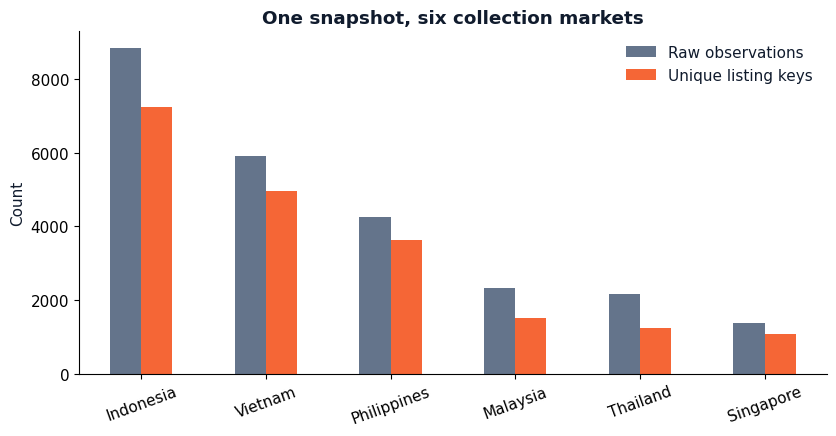

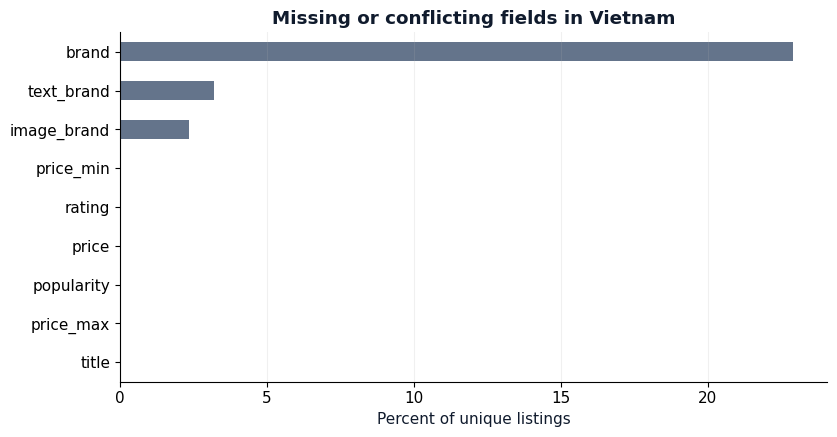

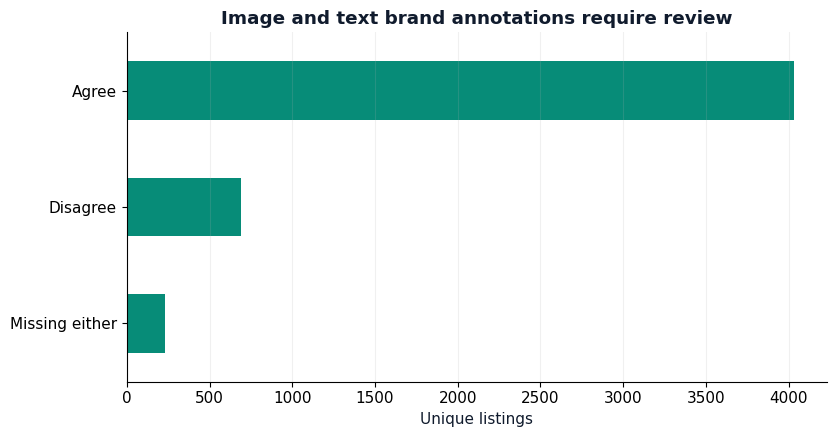

In [2]:
def choose(*names, required=False):
    found=next((n for n in names if n in raw.columns),None)
    if found is None and required: raise KeyError(f'Expected one of {names}; columns={raw.columns.tolist()}')
    return found
mapping={
 'title':choose('name','product_name','title','product_title','item_name',required=True),
 'price':choose('price','current_price','price_current','selling_price','product_price',required=True),
 'brand':choose('brand','original_brand','brand_name','source_brand','raw_brand'),
 'price_min':choose('price_min','min_price'),
 'price_max':choose('price_max','max_price'),
 'popularity':choose('monthly_sold','sold','history_sold'),
 'rating':choose('rating','rating_star','rating_avg','rating_average'),
 'image_brand':choose('image_brand','brand_image','brand_from_image','image_based_brand','image_predicted_brand','image_brand_name','brand_image_3_flash_thinking'),
 'text_brand':choose('text_brand','brand_text','brand_from_text','text_based_brand','text_predicted_brand','text_brand_name','brand_text_3_flash_thinking')
}
print('Source mapping:',mapping)
def number(s):
    return pd.to_numeric(s.astype('string').str.replace(',','',regex=False).str.strip(),errors='coerce')
def norm(s):
    if pd.isna(s): return ''
    return re.sub(r'\s+',' ',unicodedata.normalize('NFKC',str(s)).casefold()).strip()
w=raw[keys+['_workbook']].copy()
for c,src in mapping.items():
    w[c]=raw[src] if src else pd.NA
for c in ['price','price_min','price_max','popularity','rating']: w[c]=number(w[c])
for c in ['title','brand','image_brand','text_brand']: w[c]=w[c].map(norm).replace('',pd.NA)
for c in ['brand','image_brand','text_brand']: w[c]=w[c].replace(['none','nan','no brand','unknown','n/a','null','-','not available','no_brand'],pd.NA)
for c in ['price','price_min','price_max']: w[c]=w[c].where(w[c]>0)
w['popularity']=w.popularity.where(w.popularity>=0)
w['rating']=w.rating.where(w.rating.between(0,5))
groups=w.groupby(keys,sort=False,dropna=False)
conflict=groups[list(mapping)].nunique(dropna=True).gt(1)
clean=groups[list(mapping)].first().reset_index()
for c in mapping: clean.loc[conflict[c].to_numpy(),c]=pd.NA
clean['price_conflict']=conflict.price.to_numpy()
clean['brand_conflict']=conflict.brand.to_numpy()
clean['variant_range_known']=clean.price_min.notna() & clean.price_max.notna()
clean['single_price']=clean.variant_range_known & clean.price_min.eq(clean.price_max) & clean.price.eq(clean.price_min)
coverage=raw.groupby('market').size().rename('observations').to_frame().join(clean.groupby('market').size().rename('listings')).join(clean.groupby('market').shop_id.nunique().rename('shops'))
coverage['repeat_pct']=(1-coverage.listings/coverage.observations)*100
coverage=coverage.sort_values('observations',ascending=False)
display(coverage)
vn=clean[clean.market.eq('Vietnam')].copy()
assert len(vn)==4956 and vn.shop_id.nunique()==1017
display(vn[list(mapping)].isna().mean().mul(100).round(1).rename('missing_pct').to_frame())
def save_table(df,name):
    df.to_csv(TAB/f'{name}.csv')
def save(fig,name):
    fig.tight_layout()
    fig.savefig(FIG/f'{name}.png',dpi=180,bbox_inches='tight')
    plt.show(); plt.close(fig)
def bars(s,title,xlabel,name,color=ORANGE):
    fig,ax=plt.subplots(figsize=(8.5,4.5))
    s.sort_values().plot.barh(ax=ax,color=color)
    ax.set(title=title,xlabel=xlabel,ylabel='')
    ax.grid(axis='x',alpha=.18)
    save(fig,name)
save_table(coverage,'coverage')
fig,ax=plt.subplots(figsize=(8.5,4.5))
coverage[['observations','listings']].plot.bar(ax=ax,color=[GRAY,ORANGE],rot=20)
ax.set(title='One snapshot, six collection markets',ylabel='Count',xlabel='')
ax.legend(['Raw observations','Unique listing keys'],frameon=False)
save(fig,'01_coverage')
missing=vn[list(mapping)].isna().mean().mul(100)
bars(missing,'Missing or conflicting fields in Vietnam','Percent of unique listings','02_quality',GRAY)
save_table(missing.rename('missing_pct').to_frame(),'missingness')
both=vn.dropna(subset=['image_brand','text_brand'])
agreement=int(both.image_brand.eq(both.text_brand).sum())
disagreement=len(both)-agreement
bars(pd.Series({'Agree':agreement,'Disagree':disagreement,'Missing either':len(vn)-len(both)}),'Image and text brand annotations require review','Unique listings','13_brand_agreement',TEAL)



**Business implication:** The regional sample is a potential expansion research asset, not a market census. Missing or inconsistent product attributes create a quality barrier that ShopScope must surface, not conceal.

## 3. Vietnam market intelligence
Study recorded asking prices and the observed competitive landscape. Each chart has a business decision attached. The price is the recorded listing price, not necessarily a selected variant or checkout price.

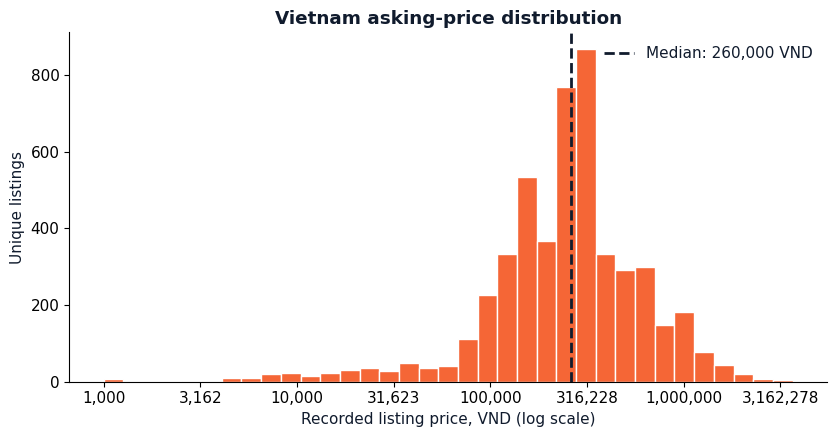

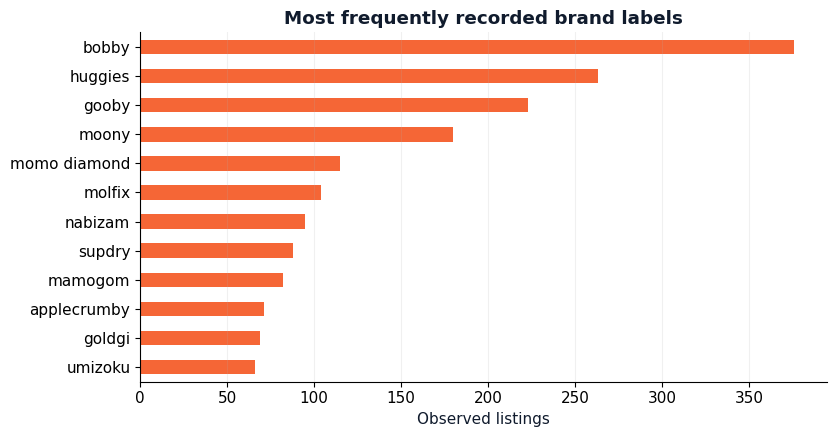

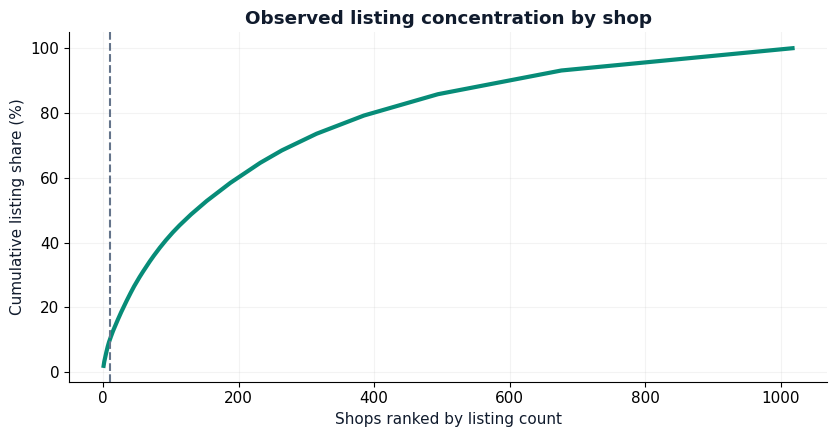

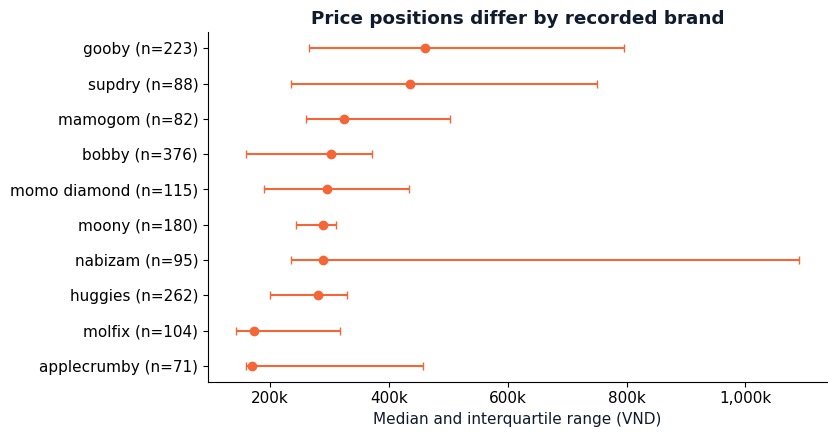

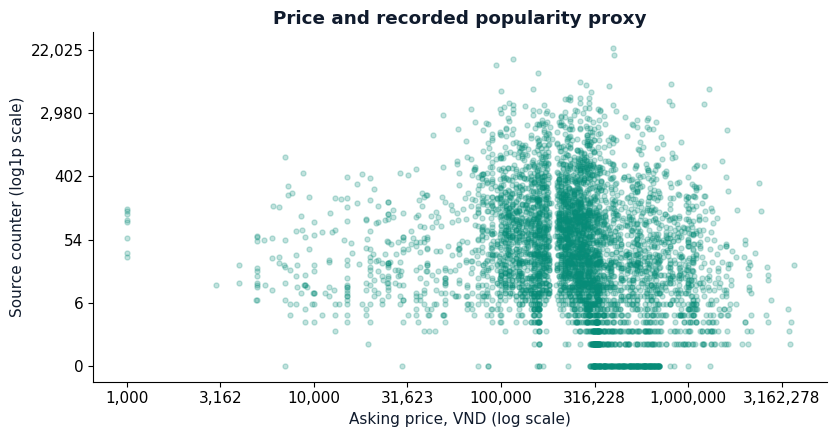

Median asking price: 260,000 VND; valid listings: 4,955
Top ten shops account for 9.9% of observed listings.
Most frequent raw brand label: bobby (376 listings).


In [3]:
valid=vn.price.dropna()
assert len(valid)>0, 'No usable Vietnam prices'
q=valid.quantile([.25,.5,.75])
fig,ax=plt.subplots(figsize=(8.5,4.5))
ax.hist(np.log10(valid),bins=35,color=ORANGE,edgecolor='white')
ax.axvline(np.log10(q.loc[.5]),color=NAVY,ls='--',lw=2,label=f'Median: {q.loc[.5]:,.0f} VND')
ax.xaxis.set_major_formatter(FuncFormatter(lambda x,pos:f'{10**x:,.0f}'))
ax.set(title='Vietnam asking-price distribution',xlabel='Recorded listing price, VND (log scale)',ylabel='Unique listings')
ax.legend(frameon=False); save(fig,'03_price')
brand=vn.brand.dropna().value_counts()
if not brand.empty: bars(brand.head(12),'Most frequently recorded brand labels','Observed listings','04_brands')
else: bars(pd.Series({'No usable source labels':len(vn)}),'Brand data unavailable','Listings','04_brands',GRAY)
shops=vn.groupby('shop_id').size().sort_values(ascending=False)
fig,ax=plt.subplots(figsize=(8.5,4.5))
ax.plot(np.arange(1,len(shops)+1),shops.cumsum()/shops.sum()*100,color=TEAL,lw=3)
ax.axvline(10,color=GRAY,ls='--'); ax.set(title='Observed listing concentration by shop',xlabel='Shops ranked by listing count',ylabel='Cumulative listing share (%)'); ax.grid(alpha=.15)
save(fig,'05_concentration')
bp=vn.dropna(subset=['brand','price']).groupby('brand').price.agg(n='size',median='median',q25=lambda s:s.quantile(.25),q75=lambda s:s.quantile(.75)).query('n>=20').sort_values('n',ascending=False).head(10)
if not bp.empty:
    fig,ax=plt.subplots(figsize=(8.5,4.5)); x=bp.sort_values('median')
    ax.errorbar(x['median'],range(len(x)),xerr=[x['median']-x.q25,x.q75-x['median']],fmt='o',color=ORANGE,capsize=3)
    ax.set_yticks(range(len(x)),[f'{b} (n={n})' for b,n in zip(x.index,x.n)])
    ax.xaxis.set_major_formatter(FuncFormatter(lambda v,p:f'{v/1000:,.0f}k'))
    ax.set(title='Price positions differ by recorded brand',xlabel='Median and interquartile range (VND)'); save(fig,'06_brand_price')
else: bars(pd.Series({'Insufficient labeled brands':1}),'Brand price analysis unavailable','Status','06_brand_price',GRAY)
save_table(bp,'brand_price')
pop=vn.dropna(subset=['price','popularity'])
fig,ax=plt.subplots(figsize=(8.5,4.5))
if len(pop):
    ax.scatter(np.log10(pop.price),np.log1p(pop.popularity),alpha=.24,s=13,color=TEAL)
    ax.xaxis.set_major_formatter(FuncFormatter(lambda x,p:f'{10**x:,.0f}'))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y,p:f'{np.expm1(y):,.0f}'))
ax.set(title='Price and recorded popularity proxy',xlabel='Asking price, VND (log scale)',ylabel='Source counter (log1p scale)')
save(fig,'07_popularity')
print(f'Median asking price: {q.loc[.5]:,.0f} VND; valid listings: {len(valid):,}')
print(f'Top ten shops account for {shops.head(10).sum()/len(vn):.1%} of observed listings.')
if len(brand): print(f'Most frequent raw brand label: {brand.index[0]} ({brand.iloc[0]:,} listings).')


**Actions:** Use the distribution for initial price orientation, not for setting a final SKU price. Examine brand-specific bands only after controlling for product type and quantity. Listing concentration suggests where to inspect competing catalogs; it is not sales market share. The source popularity counter is a research signal only.

## 4. Product intelligence and pack-size reliability
Extract only explicit Vietnamese quantity and size tokens. Titles with multiple distinct size/quantity tokens are ambiguous. Require a documented equal min/max price for automatic unit-price eligibility; even then, a human must verify the physical product, pack and variant. Missing evidence causes abstention.

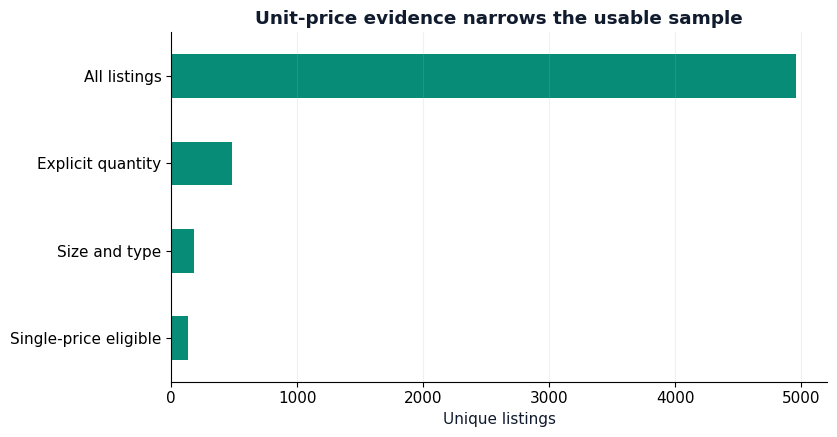

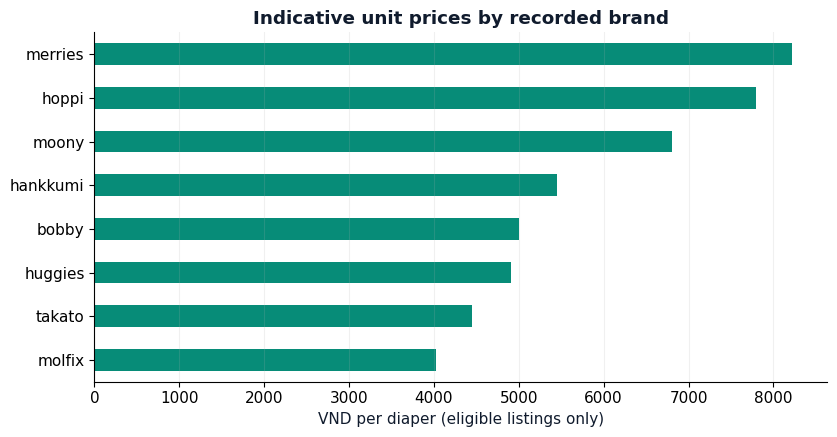

In [4]:
qty_re=re.compile(r'(?<!\d)(\d{1,3})\s*(?:miếng|mieng|chiếc|chiec|pcs?|pieces?|cái|cai)(?!\w)',re.I)
size_re=re.compile(r'(?<!\w)(?:size\s*|sz\s*)?(nb|xxxl|xxl|xl|xs|s|m|l)(?!\w)',re.I)
def extract(t):
    t=norm(t)
    quantities={int(x) for x in qty_re.findall(t) if 5<=int(x)<=200} | {int(x) for x in re.findall(r'(?<!\w)(?:nb|xxxl|xxl|xl|xs|s|m|l)(\d{1,3})(?!\w)',t) if 5<=int(x)<=200}
    sizes={x.upper() for x in size_re.findall(t)} | {x.upper() for x in re.findall(r'(?<!\w)(nb|xxxl|xxl|xl|xs|s|m|l)(?=\d{1,3}(?!\d))',t)}
    pants=bool(re.search(r'(?:bỉm|tã)\s+quần|\bpants\b|\bquần\b',t))
    tape=bool(re.search(r'(?:bỉm|tã)\s+dán|\btape\b|\bdán\b',t))
    typ='Pants' if pants and not tape else 'Tape' if tape and not pants else None
    bundle=bool(re.search(r'combo|thùng|[x×]\s*\d+\b|\b(?:[2-9]|\d{2,})\s*(?:gói|bịch|pack)|tặng|quà|set\b|lốc|người lớn|người già|miếng lót|adult|\b2xl\b|\b3xl\b',t))
    return pd.Series({'quantity':next(iter(quantities)) if len(quantities)==1 and not bundle else np.nan,'size':next(iter(sizes)) if len(sizes)==1 else None,'type':typ,'bundle':bundle})
vn=vn.join(vn.title.apply(extract))
vn['unit_eligible']=vn.quantity.notna() & vn['size'].notna() & vn['type'].notna() & vn.single_price & vn.price.notna() & ~vn.bundle
vn['unit_price']=vn.price.div(vn.quantity).where(vn.unit_eligible)
stages=pd.Series({'All listings':len(vn),'Explicit quantity':int(vn.quantity.notna().sum()),'Size and type':int((vn.quantity.notna()&vn['size'].notna()&vn['type'].notna()).sum()),'Single-price eligible':int(vn.unit_eligible.sum())})
bars(stages,'Unit-price evidence narrows the usable sample','Unique listings','08_eligibility',TEAL)
save_table(stages.rename('n').to_frame(),'eligibility')
units=vn.dropna(subset=['unit_price','brand'])
unit_table=units.groupby('brand').unit_price.agg(n='size',median='median').query('n>=5').sort_values('n',ascending=False).head(12)
if len(unit_table): bars(unit_table['median'],'Indicative unit prices by recorded brand','VND per diaper (eligible listings only)','09_unit_price',TEAL)
else: bars(pd.Series({'No sufficiently supported group':0}),'Unit-price benchmark withheld','Eligible brand groups','09_unit_price',GRAY)
save_table(unit_table,'unit_prices')


## 5. Comparable product retrieval and evaluation protocol
The baseline retrieves same normalized title across distinct shops. A char n-gram TF-IDF model ranks near matches after mandatory brand, size, type and quantity constraints. It is a candidate generator, not a verified equivalent-SKU classifier. Export a review queue and report coverage; do not invent accuracy labels. The notebook deliberately withholds precision/recall until a human-reviewed label file exists.

In [5]:
pool=vn[vn.unit_eligible & vn.brand.notna() & vn.title.notna()].copy().reset_index(drop=True)
attrs=['brand','size','type','quantity']
pairs=[]
if len(pool)>=2:
    tf=TfidfVectorizer(analyzer='char',ngram_range=(3,5),min_df=1).fit_transform(pool.title)
    for _,g in pool.groupby(attrs):
        if g.shop_id.nunique()<2: continue
        ids=g.index.to_numpy()
        for i in ids[:min(12,len(ids))]:
            scores=cosine_similarity(tf[i],tf[ids]).ravel()
            candidates=[(float(s),int(j)) for s,j in zip(scores,ids) if pool.at[i,'shop_id']!=pool.at[j,'shop_id']]
            for s,j in sorted(candidates,reverse=True)[:5]:
                pairs.append({'query_product_id':pool.at[i,'product_id'],'query_shop_id':pool.at[i,'shop_id'],'candidate_product_id':pool.at[j,'product_id'],'candidate_shop_id':pool.at[j,'shop_id'],'score':s,'exact_title':bool(pool.at[i,'title']==pool.at[j,'title'])})
review=pd.DataFrame(pairs,columns=['query_product_id','query_shop_id','candidate_product_id','candidate_shop_id','score','exact_title'])
review=review.drop_duplicates(subset=['query_product_id','query_shop_id','candidate_product_id','candidate_shop_id']).head(300)
review['human_equivalent']=pd.NA
# This is private, locally generated review material; never included in public exports.
private=OUT/'private'; private.mkdir(exist_ok=True)
review.to_csv(private/'matching_review_queue.csv',index=False)
metrics={'eligible_pool':len(pool),'candidate_pairs':len(review),'exact_title_candidates':int(review.exact_title.sum()),'evaluation_status':'Not validated: manual labels required'}
labels=ROOT/'evaluation'/'reviewed_pairs.csv'
if labels.exists() and len(review):
    from sklearn.metrics import precision_score, recall_score, f1_score
    idcols=['query_product_id','query_shop_id','candidate_product_id','candidate_shop_id']
    truth=pd.read_csv(labels,dtype={c:str for c in idcols})
    z=review.drop(columns='human_equivalent').merge(truth[idcols+['human_equivalent']],on=idcols,validate='one_to_one')
    z=z[z.human_equivalent.isin([0,1])]
    if len(z) and z.human_equivalent.nunique()==2:
        y=z.human_equivalent.astype(int)
        for name,pred in [('exact_title',z.exact_title),('tfidf_at_0_85',z.score>=.85)]:
            metrics[name]={'precision':precision_score(y,pred,zero_division=0),'recall_on_reviewed_candidates':recall_score(y,pred,zero_division=0),'f1':f1_score(y,pred,zero_division=0)}
        metrics.update(evaluation_status='Reviewed candidate subset; not full retrieval recall',reviewed_pairs=len(z))
display(metrics)


{'eligible_pool': 119,
 'candidate_pairs': 20,
 'exact_title_candidates': 2,
 'evaluation_status': 'Not validated: manual labels required'}

## 6. Opportunity discovery
Plot observed competitor counts against median source popularity proxies for recorded brand segments with at least 20 listings and three shops. This is a brand-level screening tool, not a SKU-level market-gap claim. This is a prioritization tool for follow-up research, not a prediction of sales or profit. Use within-Vietnam ranks rather than comparisons of different currencies or unverified sales windows.

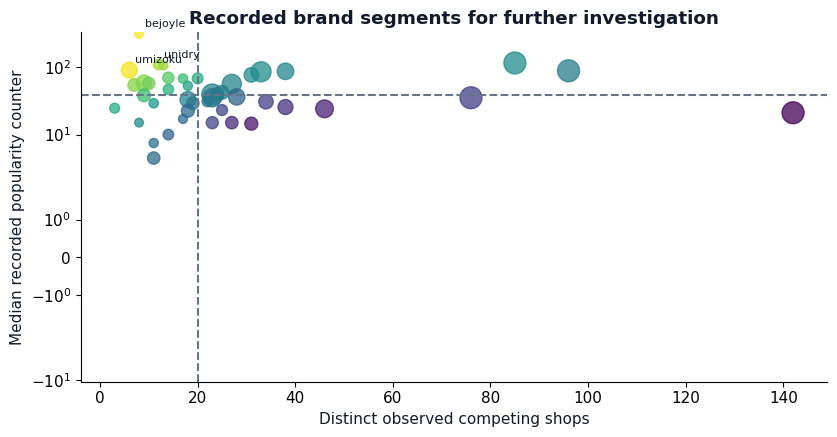

In [6]:
seg=vn.dropna(subset=['brand','popularity']).groupby('brand').agg(n=('product_id','size'),shops=('shop_id','nunique'),proxy=('popularity','median')).query('n>=20 and shops>=3').reset_index()
seg['segment']=seg.brand
if len(seg):
    seg['score']=.5*seg.proxy.rank(pct=True)+.5*(1-seg.shops.rank(pct=True))
    seg=seg.sort_values('score',ascending=False)
fig,ax=plt.subplots(figsize=(8.5,4.5))
if len(seg):
    ax.scatter(seg.shops,seg.proxy,s=np.clip(seg.n*2,25,250),c=seg.score,cmap='viridis',alpha=.75)
    ax.axvline(seg.shops.median(),color=GRAY,ls='--'); ax.axhline(seg.proxy.median(),color=GRAY,ls='--')
    ax.set_yscale('symlog')
    for _,r in seg.head(3).iterrows(): ax.annotate(r.segment,(r.shops,r.proxy),xytext=(4,5),textcoords='offset points',fontsize=8)
ax.set(title='Recorded brand segments for further investigation',xlabel='Distinct observed competing shops',ylabel='Median recorded popularity counter')
save(fig,'10_opportunity')
save_table(seg.drop(columns=['brand','type','size'],errors='ignore'),'opportunities')


## 7. Margin-aware pricing decision
Use a cost floor and observed comparable price band, not a demand forecast. A demo cohort is selected deterministically from exact-title, attribute-consistent listings at different shops; it is a provisional benchmark, not human-verified ground truth. If no eligible cohort exists, show a clearly labeled brand-level orientation band and an illustrative cost floor, but abstain from recommending a SKU price. Cost and fee inputs are explicitly hypothetical.

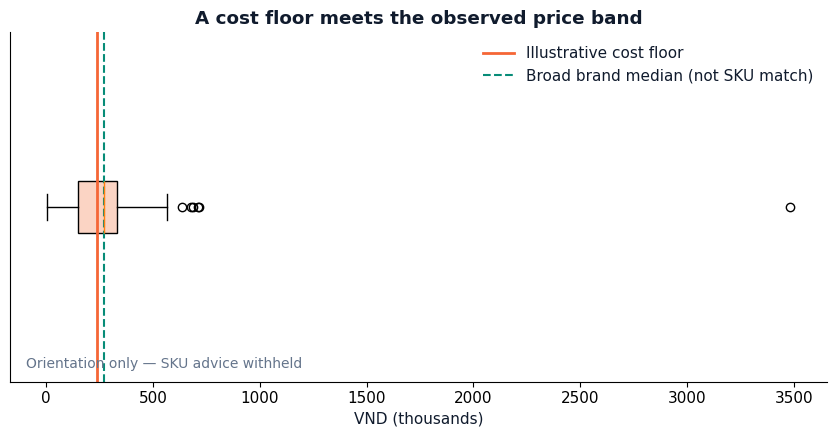

{'status': 'ABSTAIN: no cohort with three distinct shops',
 'orientation_brand': 'bobby',
 'orientation_shops': 142,
 'orientation_q25': 151355.0,
 'orientation_median': 269500.0,
 'orientation_q75': 334250.0,
 'cost_assumption': 162000,
 'floor': 239000,
 'fee_assumption': 0.12,
 'margin_assumption': 0.2}

In [7]:
def price_advice(cost,fee,margin,prices):
    if not (cost>0 and 0<=fee<1 and 0<=margin<1 and fee+margin<1): raise ValueError('Invalid economic assumptions')
    floor=math.ceil(cost/(1-fee-margin)/1000)*1000
    p=pd.Series(prices,dtype=float).dropna()
    if len(p)<3: return {'floor':floor,'status':'ABSTAIN: fewer than three comparable shop prices'}
    lo,med,hi=p.quantile([.25,.5,.75])
    return {'floor':floor,'q25':float(lo),'median':float(med),'q75':float(hi),'status':'Test a price within the feasible band' if math.ceil(max(lo,floor)/1000)*1000<=hi else 'Reduce costs or differentiate before entering','suggested_test_price':int(math.ceil(max(lo,floor)/1000)*1000) if math.ceil(max(lo,floor)/1000)*1000<=hi else None}
cohorts=pool.groupby(attrs+['title'],dropna=False).shop_id.nunique().sort_values(ascending=False) if len(pool) else pd.Series(dtype=int)
case={'status':'ABSTAIN: no cohort with three distinct shops'}
fig,ax=plt.subplots(figsize=(8.5,4.5))
if len(cohorts) and cohorts.iloc[0]>=3:
    group=pool
    for k,v in zip(attrs+['title'],cohorts.index[0]): group=group[group[k].eq(v)]
    prices=group.groupby('shop_id').price.median()
    cost=max(1000,round(float(prices.median())*.60/1000)*1000)
    case=price_advice(cost,.12,.20,prices)
    case.update({'brand':str(group.brand.iloc[0]),'size':str(group['size'].iloc[0]),'type':str(group['type'].iloc[0]),'quantity':int(group.quantity.iloc[0]),'shops':len(prices),'cost_assumption':cost,'fee_assumption':.12,'margin_assumption':.20})
    ax.boxplot(prices/1000,vert=False,patch_artist=True,boxprops={'facecolor':'#FBD4C4'})
    ax.axvline(case['floor']/1000,color=ORANGE,lw=2,label='Cost floor (assumed inputs)')
    ax.axvline(case['median']/1000,color=TEAL,ls='--',label='Historical median')
    ax.legend(frameon=False)
else:
    # An actual broad brand-price distribution is orientation only, never a SKU benchmark.
    label=brand.index[0] if len(brand) else None
    broad=vn[vn.brand.eq(label)].dropna(subset=['price']) if label else vn.dropna(subset=['price'])
    prices=broad.groupby('shop_id').price.median()
    if len(prices)>=3:
        lo,med,hi=prices.quantile([.25,.5,.75])
        cost=max(1000,round(float(med)*.60/1000)*1000)
        floor=math.ceil(cost/(1-.12-.20)/1000)*1000
        case.update({'orientation_brand':str(label),'orientation_shops':len(prices),'orientation_q25':float(lo),'orientation_median':float(med),'orientation_q75':float(hi),'cost_assumption':cost,'floor':floor,'fee_assumption':.12,'margin_assumption':.20})
        ax.boxplot(prices/1000,vert=False,patch_artist=True,boxprops={'facecolor':'#FBD4C4'})
        ax.axvline(floor/1000,color=ORANGE,lw=2,label='Illustrative cost floor')
        ax.axvline(med/1000,color=TEAL,ls='--',label='Broad brand median (not SKU match)')
        ax.legend(frameon=False)
        ax.text(.02,.04,'Orientation only — SKU advice withheld',transform=ax.transAxes,fontsize=10,color=GRAY)
    else:
        ax.text(.5,.5,'Insufficient comparable evidence — abstain',ha='center',va='center',transform=ax.transAxes)
ax.set(title='A cost floor meets the observed price band',xlabel='VND (thousands)',yticks=[])
save(fig,'11_pricing_case')
display(case)
assert price_advice(150000,.12,.2,[220000,240000,260000])['floor']==221000
assert price_advice(150000,.12,.2,[240000])['status'].startswith('ABSTAIN')


## 8. Startup economics — transparent scenarios
Assume a single Pro subscription at VND 99,000/month, variable servicing cost of VND 20,000 per account per month and fixed monthly operating cost of VND 20 million. These are planning assumptions, not customer demand or observed financial results. Actual data licensing and acquisition cost must be quoted before commercialization.

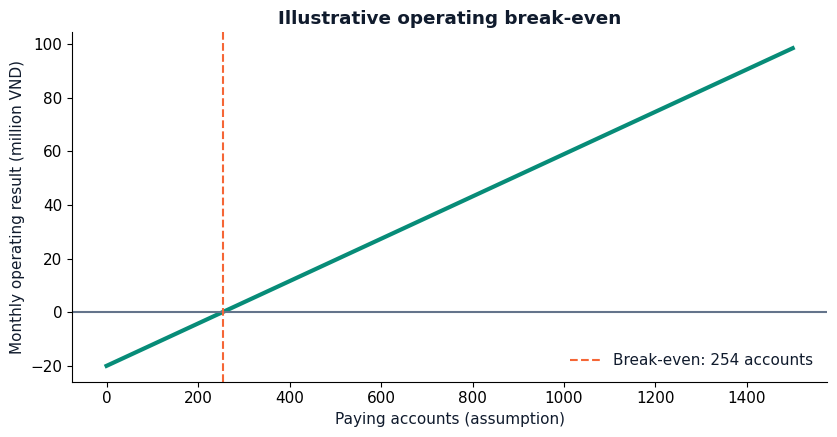

,scenario,paid_accounts,mrr,arr_run_rate,monthly_operating_result
0,Conservative,100,9900000,118800000,-12100000
1,Base,500,49500000,594000000,19500000
2,Optimistic,1500,148500000,1782000000,98500000


In [8]:
sub=99000; variable=20000; fixed=20000000
finance=pd.DataFrame({'scenario':['Conservative','Base','Optimistic'],'paid_accounts':[100,500,1500]})
finance['mrr']=finance.paid_accounts*sub
finance['arr_run_rate']=finance.mrr*12
finance['monthly_operating_result']=finance.paid_accounts*(sub-variable)-fixed
breakeven=math.ceil(fixed/(sub-variable))
fig,ax=plt.subplots(figsize=(8.5,4.5))
x=np.arange(0,1501)
ax.plot(x,(x*(sub-variable)-fixed)/1e6,color=TEAL,lw=3)
ax.axhline(0,color=GRAY); ax.axvline(breakeven,color=ORANGE,ls='--',label=f'Break-even: {breakeven} accounts')
ax.set(title='Illustrative operating break-even',xlabel='Paying accounts (assumption)',ylabel='Monthly operating result (million VND)')
ax.legend(frameon=False); save(fig,'12_finance')
display(finance); save_table(finance.set_index('scenario'),'financial_scenarios')


## 9. Additional decision evidence and scenario sensitivity
The additional charts quantify repeat-key risk, variant price ambiguity, data sufficiency and competition. The market context chart uses explicitly sourced external aggregate statistics; the financial sensitivity chart uses planning assumptions. Neither is a finding from the Shopee workbook.


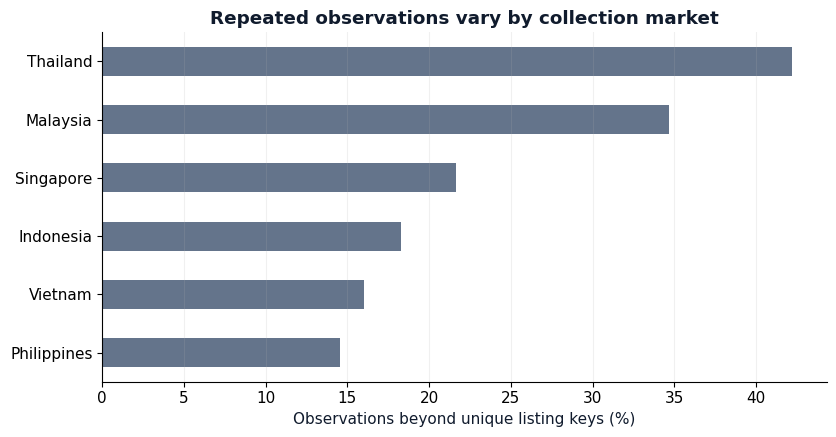

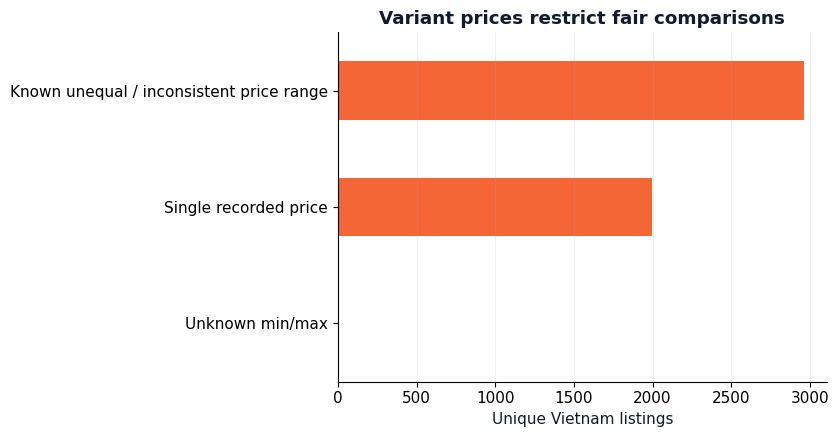

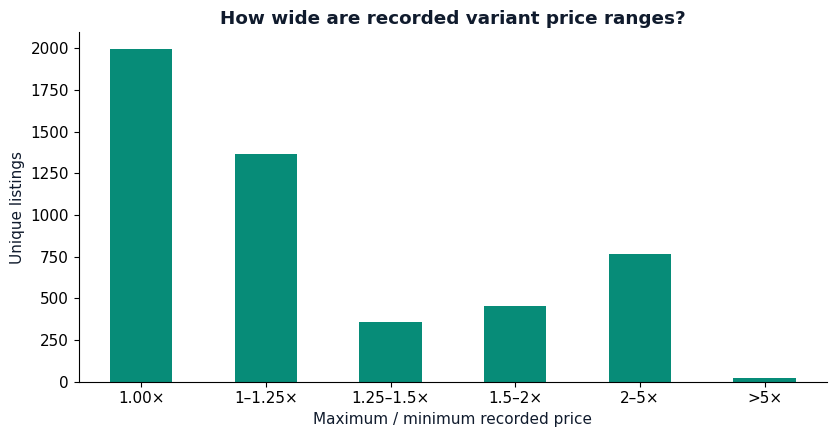

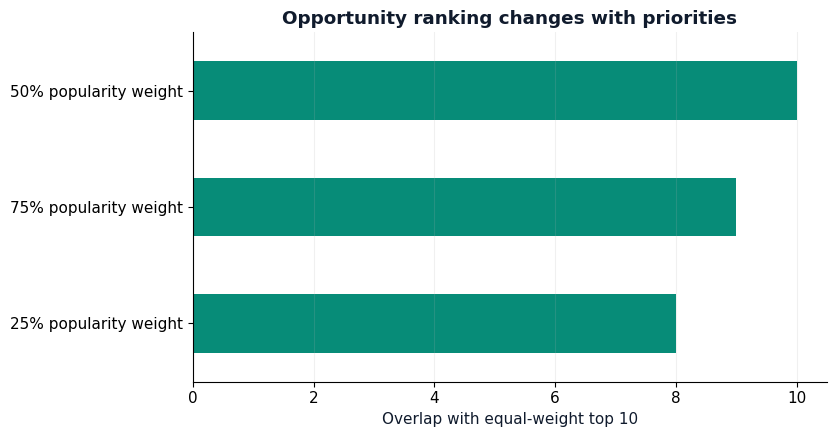

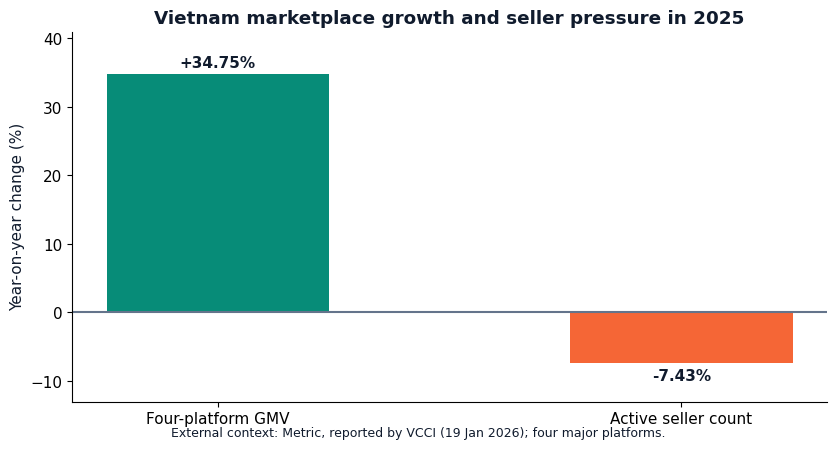

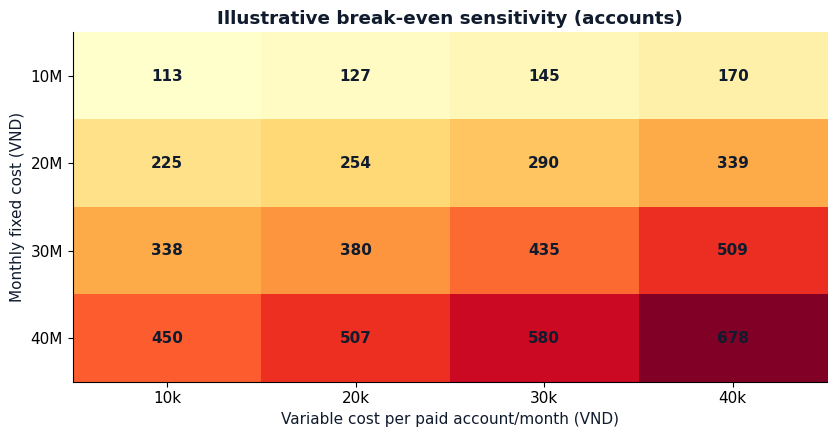

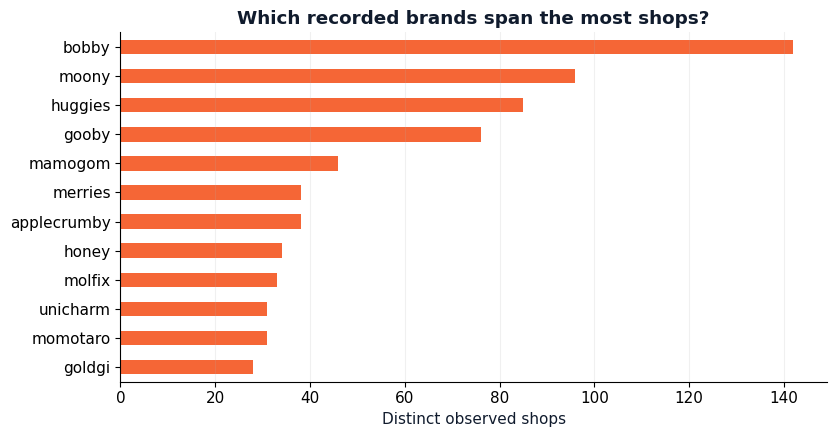

In [9]:
bars(coverage.repeat_pct,'Repeated observations vary by collection market','Observations beyond unique listing keys (%)','14_repeats',GRAY)
variant_status=pd.Series({'Single recorded price':int(vn.single_price.sum()),'Known unequal / inconsistent price range':int((vn.variant_range_known & ~vn.single_price).sum()),'Unknown min/max':int((~vn.variant_range_known).sum())})
assert variant_status.sum()==len(vn)
bars(variant_status,'Variant prices restrict fair comparisons','Unique Vietnam listings','15_variant_risk',ORANGE)
vr=vn[vn.variant_range_known & vn.price_max.ge(vn.price_min) & vn.price_min.gt(0)].copy()
ratio=(vr.price_max/vr.price_min).astype(float)
ratio_bins=pd.cut(ratio,[0,1,1.25,1.5,2,5,np.inf],labels=['1.00×','1–1.25×','1.25–1.5×','1.5–2×','2–5×','>5×'],include_lowest=True).value_counts(sort=False)
fig,ax=plt.subplots(figsize=(8.5,4.5));ratio_bins.plot.bar(ax=ax,color=TEAL,rot=0)
ax.set(title='How wide are recorded variant price ranges?',xlabel='Maximum / minimum recorded price',ylabel='Unique listings');save(fig,'16_variant_spread')
save_table(variant_status.rename('n').to_frame(),'variant_status')
# Weight sensitivity: overlap of top 10 across candidate screening formulas.
sensitivity={}
if len(seg):
    for weight in [.25,.5,.75]:
        score=weight*seg.proxy.rank(pct=True)+(1-weight)*(1-seg.shops.rank(pct=True))
        sensitivity[str(weight)]=seg.assign(sensitivity_score=score).nlargest(10,'sensitivity_score').segment.tolist()
    common=set(sensitivity['0.25']) & set(sensitivity['0.5']) & set(sensitivity['0.75'])
    overlap=pd.Series({f'{float(w):.0%} popularity weight':len(set(x)&set(sensitivity['0.5'])) for w,x in sensitivity.items()})
else:
    common=set();overlap=pd.Series({'No supported segments':0})
bars(overlap,'Opportunity ranking changes with priorities','Overlap with equal-weight top 10','17_opportunity_sensitivity',TEAL)
# Source: Metric, reported by VCCI, 19 January 2026. 2024 values are reconstructed,
# not separate published observations; the two measures have different units.
market_context={'gmv_2025_trillion_vnd':429.7,'gmv_yoy':.3475,'active_sellers_2025':601800,'seller_yoy':-.0743,'source':'https://en.vcci.com.vn/economic-news/online-retail-sales-in-vietnam-jump-35-to-over-16-bln-in-2025-report-114817'}
fig,ax=plt.subplots(figsize=(8.5,4.5))
ax.bar(['Four-platform GMV','Active seller count'],[34.75,-7.43],color=[TEAL,ORANGE],width=.48)
ax.axhline(0,color=GRAY);ax.set(title='Vietnam marketplace growth and seller pressure in 2025',ylabel='Year-on-year change (%)')
for j,val in enumerate([34.75,-7.43]): ax.text(j,val+(1 if val>=0 else -2.5),f'{val:+.2f}%',ha='center',fontweight='bold')
ax.set_ylim(-13,41);fig.text(.5,.015,'External context: Metric, reported by VCCI (19 Jan 2026); four major platforms.',ha='center',fontsize=9)
save(fig,'18_market_context')
# Data acquisition and support costs remain unverified; show break-even sensitivity.
fixed_grid=[10000000,20000000,30000000,40000000];variable_grid=[10000,20000,30000,40000]
be=pd.DataFrame([[math.ceil(f/(sub-v)) for v in variable_grid] for f in fixed_grid],index=[f'{f/1e6:.0f}M' for f in fixed_grid],columns=[f'{v/1000:.0f}k' for v in variable_grid])
fig,ax=plt.subplots(figsize=(8.5,4.5));im=ax.imshow(be.values,cmap='YlOrRd',aspect='auto')
ax.set_xticks(range(len(be.columns)),be.columns);ax.set_yticks(range(len(be.index)),be.index)
for y in range(len(be.index)):
    for x in range(len(be.columns)):ax.text(x,y,str(be.iloc[y,x]),ha='center',va='center',color=NAVY,fontweight='bold')
ax.set(title='Illustrative break-even sensitivity (accounts)',xlabel='Variable cost per paid account/month (VND)',ylabel='Monthly fixed cost (VND)');save(fig,'19_cost_sensitivity')
save_table(be,'break_even_sensitivity')
brand_shops=vn.dropna(subset=['brand']).groupby('brand').shop_id.nunique().sort_values(ascending=False)
bars(brand_shops.head(12),'Which recorded brands span the most shops?','Distinct observed shops','20_brand_shops',ORANGE)
save_table(brand_shops.rename('shops').to_frame(),'brand_shops')


## 10. Evidence export and conclusion
All artifacts below share the exact same evidence bundle. The next step is customer validation: 15 interviews, 10 paired pricing tasks, and a paid pilot offer. No interviews, payments or product-matching ground truth are implied by this analysis.

In [10]:
def clean_json(x):
    if isinstance(x,dict): return {str(k):clean_json(v) for k,v in x.items()}
    if isinstance(x,list): return [clean_json(v) for v in x]
    if isinstance(x,(np.integer,)): return int(x)
    if isinstance(x,(np.floating,float)): return float(x) if np.isfinite(x) else None
    if isinstance(x,(np.bool_,)): return bool(x)
    return x
evidence={'source':'Easy Data | Shopee Diaper Listings: Six Markets, November 2025','crawl_date':'2025-11-18','source_url':'https://www.kaggle.com/datasets/johnphamed/shopee-diaper-listings-six-markets-november-2025','publisher_url':'https://github.com/JohnPham-easydata/Shopee-Dataset/blob/main/README.md','files':manifest,'mapping':mapping,'raw_observations':len(raw),'unique_listings':len(clean),'vn_listings':len(vn),'vn_shops':vn.shop_id.nunique(),'coverage':coverage.reset_index().to_dict('records'),'vn_valid_prices':len(valid),'vn_price_q25':q.loc[.25],'vn_price_median':q.loc[.5],'vn_price_q75':q.loc[.75],'vn_price_conflicts':int(vn.price_conflict.sum()),'vn_brand_known':int(vn.brand.notna().sum()),'top_brand':str(brand.index[0]) if len(brand) else None,'top_brand_n':int(brand.iloc[0]) if len(brand) else 0,'top10_shop_share':shops.head(10).sum()/len(vn),'eligible_units':int(vn.unit_eligible.sum()),'popularity_field':mapping['popularity'],'popularity_n':len(pop),'opportunity_segments':len(seg),'top_opportunity':str(seg.segment.iloc[0]) if len(seg) else None,'annotation_pairs':len(both),'annotation_agreement':agreement,'matching':metrics,'pricing_case':case,'finance':{'subscription':sub,'variable_cost':variable,'fixed_cost':fixed,'breakeven':breakeven,'scenarios':finance.to_dict('records')},'variant_status':variant_status.to_dict(),'variant_spread_gt_2':int((ratio>2).sum()),'variant_spread_n':len(ratio),'opportunity_stable_top10':len(common),'market_context':market_context,'brand_shop_leader':str(brand_shops.index[0]) if len(brand_shops) else None,'brand_shop_leader_n':int(brand_shops.iloc[0]) if len(brand_shops) else 0,'validation_status':'Not conducted','figures':[p.name for p in sorted(FIG.glob('*.png'))]}
evidence=clean_json(evidence)
(OUT/'evidence.json').write_text(json.dumps(evidence,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
# Local MVP: no raw data redistribution. Use private data only after downloading the original release.
vn.to_csv(private/'vietnam_analysis.csv',index=False)
display(Markdown(f"**Evidence:** {len(raw):,} observations, {len(clean):,} unique listings; {len(vn):,} Vietnamese listings across {vn.shop_id.nunique():,} shops. Historical median asking price: {q.loc[.5]:,.0f} VND (n={len(valid):,}). Eligible unit-price evidence: {vn.unit_eligible.sum():,} listings."))


**Evidence:** 24,896 observations, 19,686 unique listings; 4,956 Vietnamese listings across 1,017 shops. Historical median asking price: 260,000 VND (n=4,955). Eligible unit-price evidence: 133 listings.